#### Isolation forest is one the more advanced outlier detection/removal algorithms
Unlike IQR and Z-score -approaches, Isolation Forest is actually a machine learning algorithm, which will also remove outliers and (and partially noise) within the distribution itself.

In [10]:
# can process the whole dataset 
# and compares variables to each other instead
# of focusing on outliers on a single variable
from sklearn.ensemble import IsolationForest
import pandas as pd

# adjust the contamination rate as you see fit
# for example, if you expect 5% of the data to be outliers
# you can use 0.05 etc. 

# basically, this is how aggressive Isolation Forest will be
# increase if you think you need to detect more outliers
# decrease if you need less outliers
iso = IsolationForest(contamination=0.02) 
df = pd.read_csv("../laptop_data_cleaned.csv")



In [11]:
# converts nominal variables into binary 

from sklearn.preprocessing import OneHotEncoder
variables = ['Company','TypeName','Cpu_brand','Gpu_brand','Os']
# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)
df.head()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,0,1,0,0,0,1,0,1,0,0
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,0,1,0,0,0,1,0,1,0,0
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,0,1,0,0,0,1,0,0,1,0
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,0,1,0,0,0,1,0,1,0,0


In [12]:
# fit isolation forest
y_pred = iso.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

Inliers: 1247
Outliers: 26


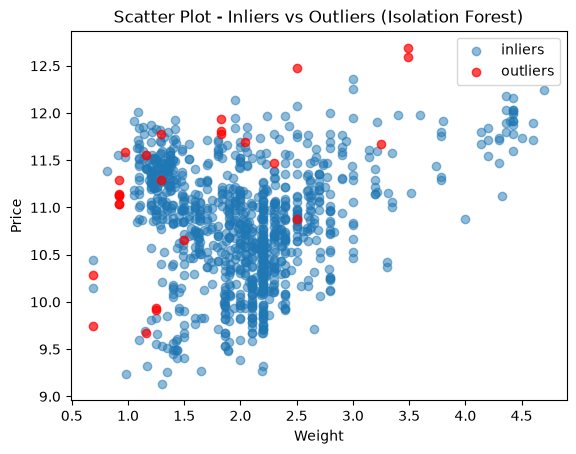

In [13]:
import matplotlib.pyplot as plt

# change the variable to inspect other views (Ram, SSD, Ppi, Weight)
variable = "Weight"
target = "Price"

inliers_sample = inliers.sample(min(1000, len(inliers)), random_state=42)
outliers_sample = outliers.sample(min(100, len(outliers)), random_state=42)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.7, color="red")

plt.xlabel(variable)
plt.ylabel(target)
plt.title("Scatter Plot - Inliers vs Outliers (Isolation Forest)")
plt.legend()
plt.show()

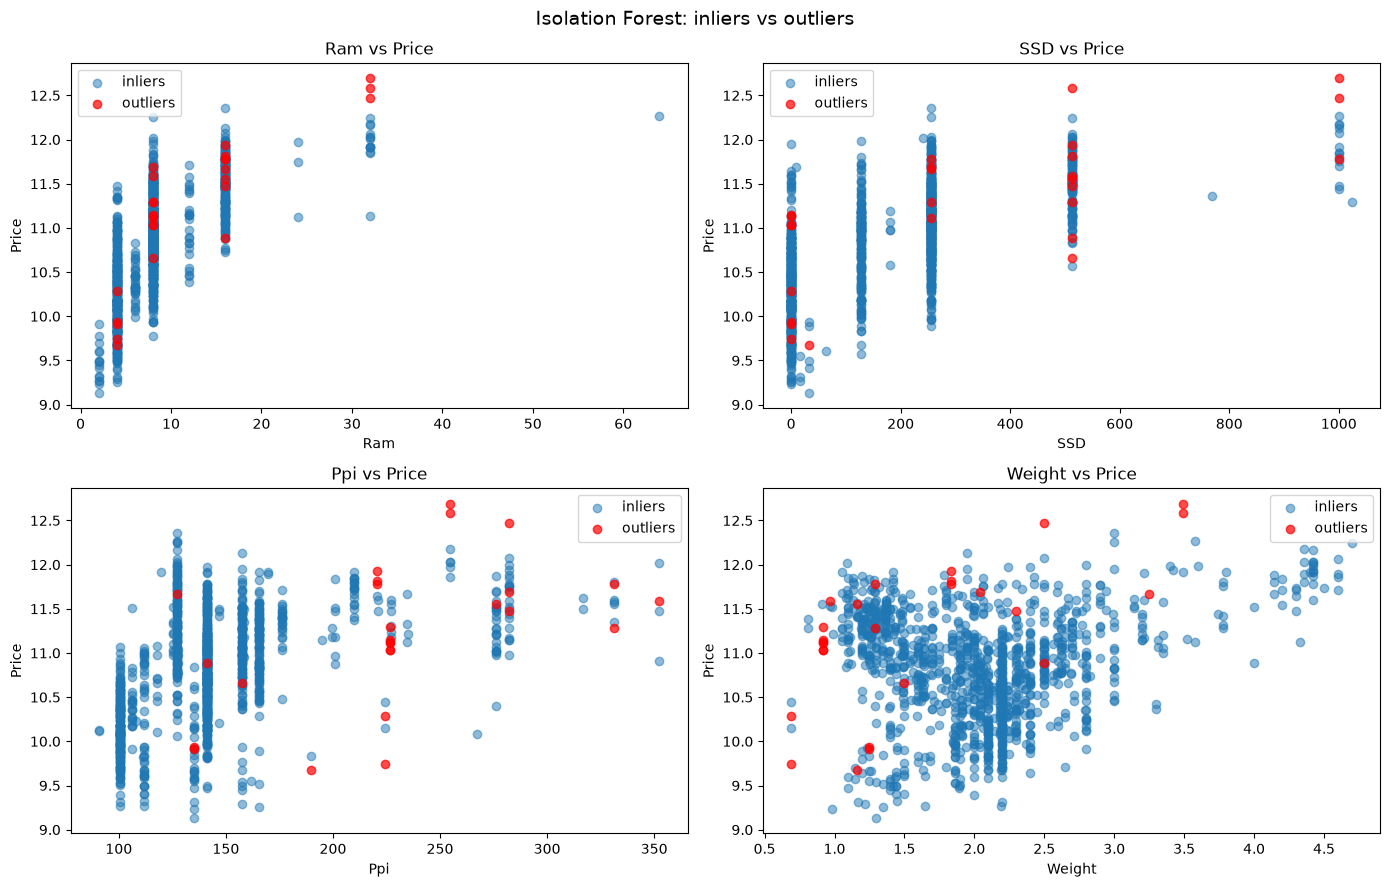

In [14]:
# Inliers vs outliers for several variables at once
import matplotlib.pyplot as plt

target = "Price"
variables = ["Ram", "SSD", "Ppi", "Weight"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, variable in zip(axes, variables):
    ax.scatter(inliers[variable], inliers[target], label="inliers", alpha=0.5)
    ax.scatter(outliers[variable], outliers[target], label="outliers", alpha=0.7, color="red")
    ax.set_xlabel(variable)
    ax.set_ylabel(target)
    ax.set_title(f"{variable} vs {target}")
    ax.legend()

plt.suptitle("Isolation Forest: inliers vs outliers", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
outliers

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
12,16,1.83,11.775302,0,1,220.534624,0,256,0,1,...,0,0,1,0,1,0,0,1,0,0
14,8,0.92,11.116331,0,1,226.415547,0,256,0,1,...,0,0,0,1,0,1,0,1,0,0
17,16,1.83,11.933438,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
50,4,0.69,9.740752,1,1,224.173809,0,0,0,0,...,0,0,0,1,0,1,0,0,1,0
81,8,0.92,11.295426,0,1,226.415547,0,512,0,1,...,0,1,0,0,0,1,0,1,0,0
146,8,0.97,11.583439,1,1,352.465147,0,512,0,0,...,0,0,0,1,0,1,0,0,0,1
179,8,1.29,11.288115,1,1,331.264236,0,256,0,0,...,0,1,0,0,0,1,0,0,0,1
196,32,3.49,12.691441,1,0,254.671349,0,1000,0,0,...,0,0,1,0,0,0,1,0,0,1
316,16,1.29,11.778996,1,1,331.264236,0,1000,0,0,...,0,0,1,0,0,1,0,0,0,1


In [16]:
#### EXTRA -  multiple variables with pairplot

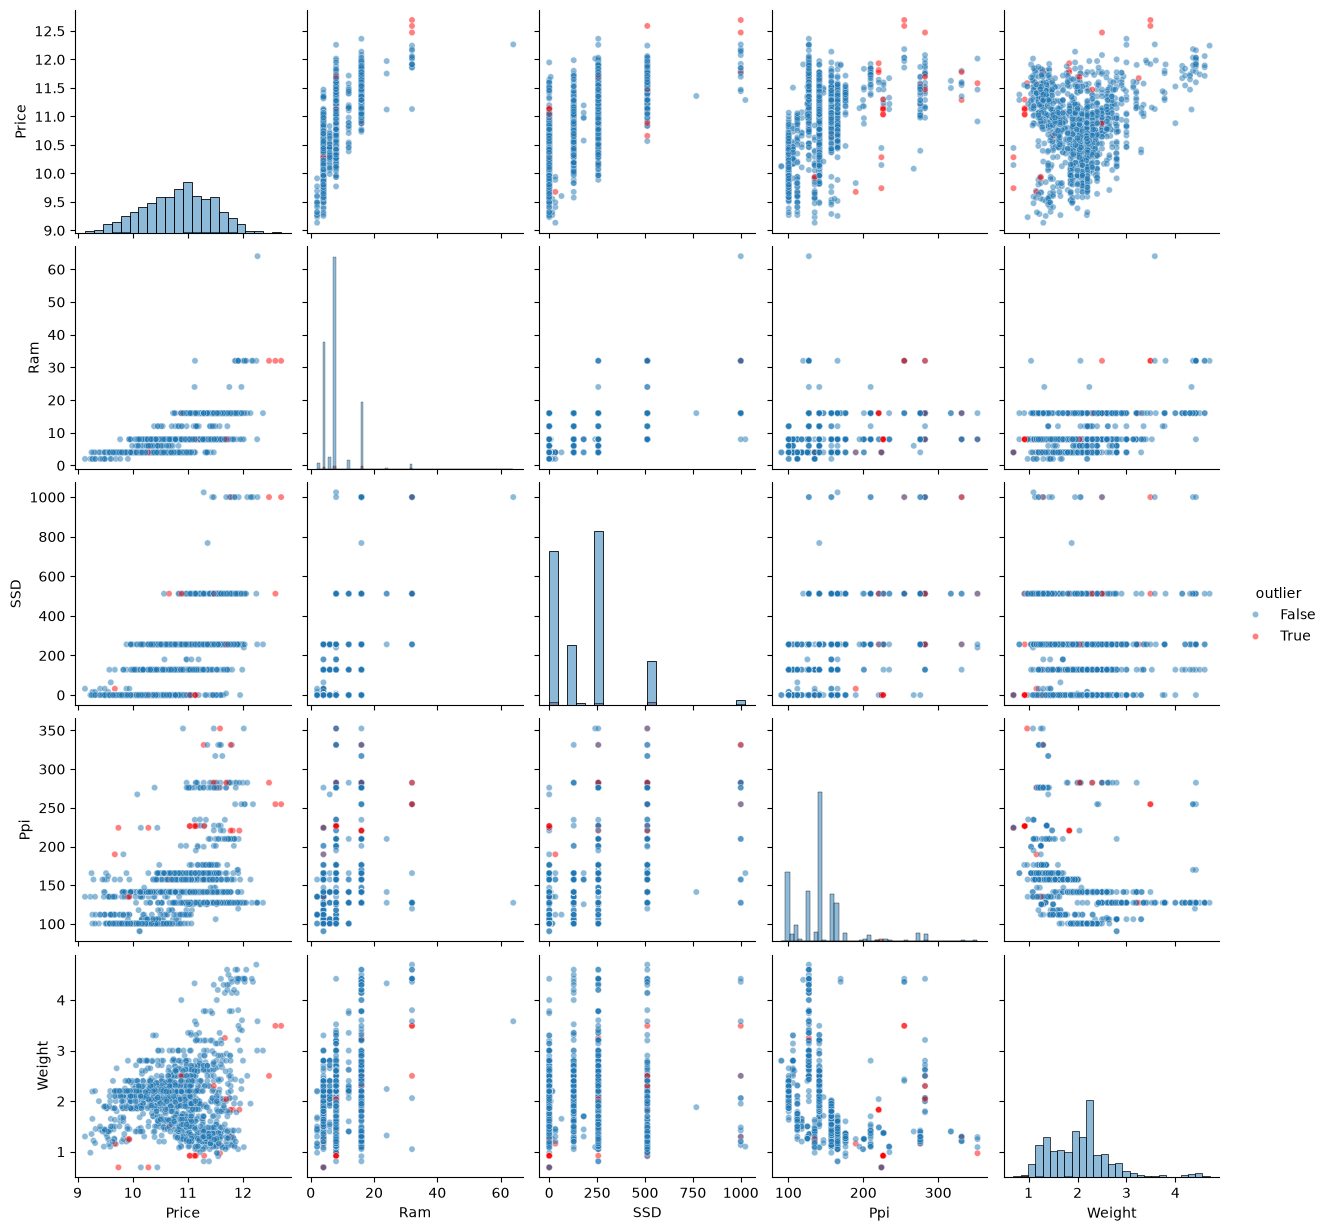

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# mark which rows Isolation Forest flagged
df["outlier"] = y_pred == -1

cols = ["Price", "Ram", "SSD", "Ppi", "Weight"]

sns.pairplot(
    df,
    vars=cols,
    hue="outlier",
    diag_kind="hist",
    palette={False: "tab:blue", True: "red"},
    plot_kws={"alpha": 0.5, "s": 20}
)

plt.show()